# ML Assignment 2: Breast Cancer Classification
M.Tech (DSE), BITS Pilani. Run on BITS Virtual Lab.

Dataset: UCI Breast Cancer Wisconsin (Diagnostic), 569 rows x 30 features.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import *

## 1. Load data and explore

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target   # 1 = benign, 0 = malignant
print('Shape:', X.shape)
print('Missing values:', X.isna().sum().sum())
print(y.value_counts())
X.describe().T.head(10)

Shape: (569, 30)
Missing values: 0
target
1    357
0    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


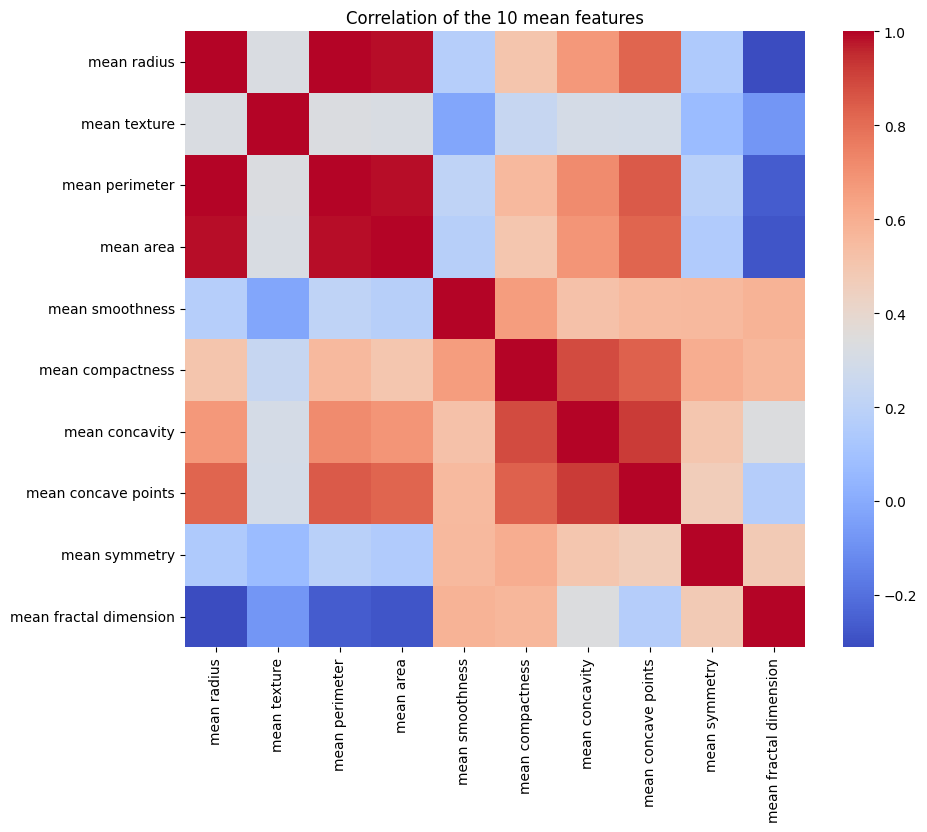

In [3]:
plt.figure(figsize=(10,8))
sns.heatmap(X.iloc[:, :10].corr(), cmap='coolwarm', annot=False)
plt.title('Correlation of the 10 mean features'); plt.show()

## 2. Train/test split (stratified 80/20)

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_tr.shape, X_te.shape)

(455, 30) (114, 30)


## 3. Define the five models

In [5]:
models = {
    'Logistic Regression': Pipeline([('s', StandardScaler()), ('m', LogisticRegression(max_iter=1000))]),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'kNN': Pipeline([('s', StandardScaler()), ('m', KNeighborsClassifier(n_neighbors=7))]),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': Pipeline([('s', StandardScaler()), ('m', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))]),
}

## 4. Train and evaluate (Accuracy, AUC, Precision, Recall, F1, MCC)

In [6]:
rows, cms = {}, {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    pred, prob = m.predict(X_te), m.predict_proba(X_te)[:, 1]
    rows[name] = {'Accuracy': accuracy_score(y_te, pred), 'AUC': roc_auc_score(y_te, prob),
                  'Precision': precision_score(y_te, pred), 'Recall': recall_score(y_te, pred),
                  'F1': f1_score(y_te, pred), 'MCC': matthews_corrcoef(y_te, pred),
                  'Train Acc': accuracy_score(y_tr, m.predict(X_tr))}
    cms[name] = confusion_matrix(y_te, pred)
results = pd.DataFrame(rows).T.round(4)
results

,Accuracy,AUC,Precision,Recall,F1,MCC,Train Acc
Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623,0.9890
Decision Tree,0.9211,0.9163,0.9565,0.9167,0.9362,0.8341,0.9934
kNN,0.9737,0.9884,0.9600,1.0000,0.9796,0.9442,0.9758
Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676,0.9407
Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623,0.9824


## 5. Confusion matrices

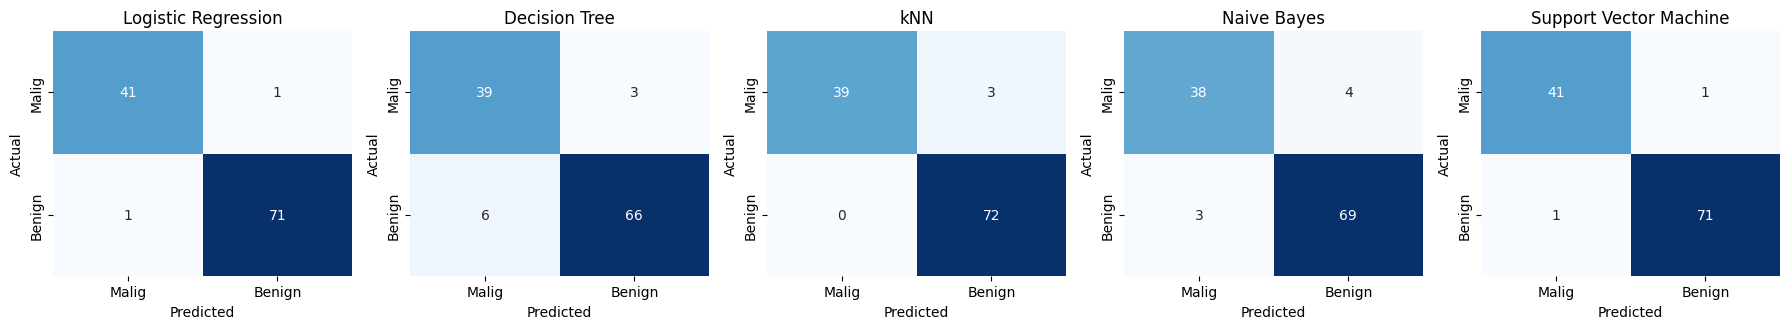

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, (n, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Malig','Benign'], yticklabels=['Malig','Benign'])
    ax.set_title(n); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 6. ROC curves

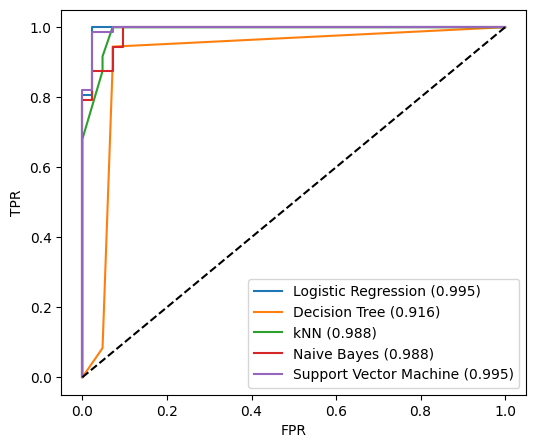

In [8]:
plt.figure(figsize=(6,5))
for n, m in models.items():
    fpr, tpr, _ = roc_curve(y_te, m.predict_proba(X_te)[:,1])
    plt.plot(fpr, tpr, label=f"{n} ({results.loc[n,'AUC']:.3f})")
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.show()

## 7. Save models and test data (used by the Streamlit app)
After this cell runs, download `test_data.csv` and the `.pkl` files, or simply run `python model/train_models.py`.

In [9]:
import joblib, os
os.makedirs('saved', exist_ok=True)
for n, m in models.items():
    joblib.dump(m, 'saved/' + n.lower().replace(' ', '_') + '.pkl')
test_df = X_te.copy(); test_df['target'] = y_te.values
test_df.to_csv('test_data.csv', index=False)
print('Saved', len(test_df), 'rows')

Saved 114 rows


## 8. Observations
The Breast Cancer Wisconsin (Diagnostic) dataset contains 569 observations and 30 numerical features. There are 357 benign cases and 212 malignant cases. The dataset has no missing values.

The following observations were made after training and evaluating the five machine learning models:

Logistic Regression: Achieved an accuracy of 98.25% and an AUC of 0.9954. It demonstrated excellent classification performance with a precision, recall, and F1-score of 98.61%. The training accuracy was 98.90%, indicating good generalization with minimal overfitting.
Decision Tree: Achieved an accuracy of 92.11% and an AUC of 0.9163. Although its training accuracy was 99.34%, its test accuracy was considerably lower. This indicates possible overfitting. The model may have learned patterns specific to the training data.
k-Nearest Neighbors (kNN): Achieved an accuracy of 97.37% and an AUC of 0.9884. It obtained a recall of 100%, meaning that all positive (benign) cases in the test set were correctly identified. Feature scaling helped improve its performance.
Naive Bayes: Achieved an accuracy of 93.86% and an AUC of 0.9878. Although its accuracy was lower than that of Logistic Regression and SVM, its AUC indicates good ability to distinguish between the two classes.
Support Vector Machine (SVM): Achieved an accuracy of 98.25% and an AUC of 0.9950. It performed similarly to Logistic Regression, with excellent precision, recall, and F1-score. Standardization of features helped the SVM model perform effectively.
Overall Comparison
Logistic Regression and Support Vector Machine achieved the highest test accuracy of 98.25%.
Logistic Regression obtained the highest AUC of 0.9954, making it the best model based on this metric.
kNN achieved the highest recall of 100%, indicating that it correctly identified all benign cases in the test dataset.
Decision Tree showed the largest difference between training and testing accuracy, suggesting overfitting.
Naive Bayes achieved a relatively high AUC despite having lower accuracy compared with the top-performing models.
StandardScaler was used for Logistic Regression, kNN, and SVM because these algorithms are sensitive to feature scales.
Conclusion
Based on the experimental results, Logistic Regression and Support Vector Machine are the best-performing models for this breast cancer classification task. Both achieved 98.25% accuracy and an F1-score of 98.61%.

Logistic Regression slightly outperformed SVM in terms of AUC. kNN also performed well, achieving 100% recall for the benign class.

Overall, the experiment demonstrates that machine learning algorithms can effectively classify breast cancer cases using diagnostic features. However, since this is a medical classification problem, further validation using cross-validation and independent datasets is necessary before considering any model for real-world clinical applications.

Best Model: Logistic Regression, based on its highest test AUC of 0.9954 and joint-best test accuracy of 98.25%.

In [10]:
# Classification reports for all models
for name, model in models.items():
    print("\n", "="*50)
    print(name)
    print("="*50)
    print(classification_report(
        y_te,
        model.predict(X_te),
        target_names=['Malignant', 'Benign']
    ))


Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Decision Tree
              precision    recall  f1-score   support

   Malignant       0.87      0.93      0.90        42
      Benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114


kNN
              precision    recall  f1-score   support

   Malignant       1.00      0.93      0.96        42
      Benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97

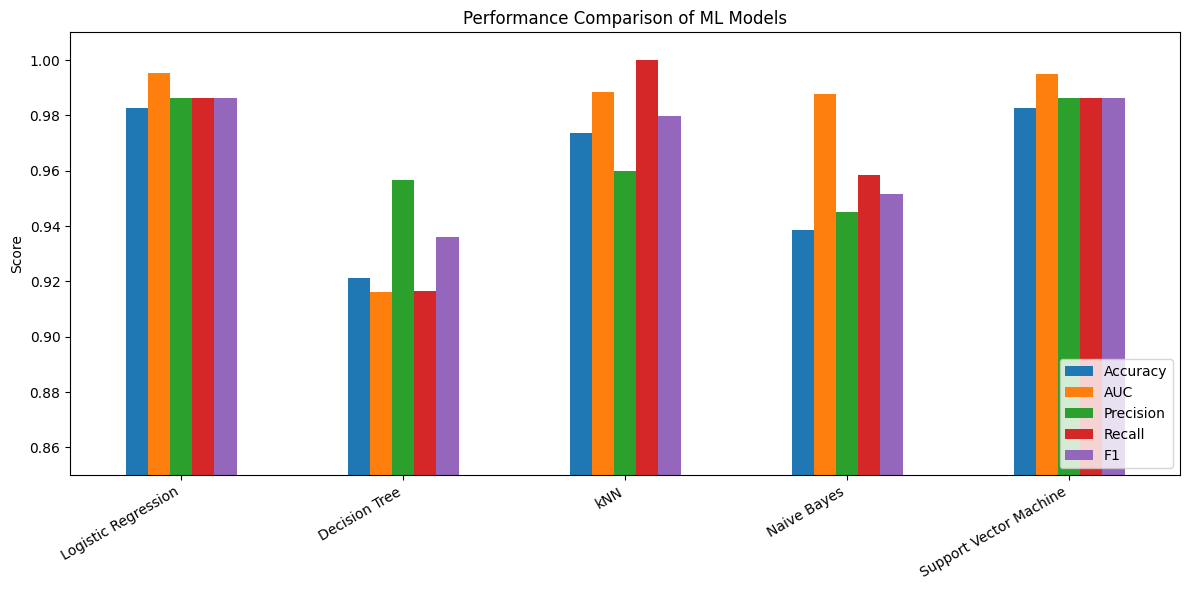

In [11]:
results[['Accuracy', 'AUC', 'Precision', 'Recall', 'F1']].plot(
    kind='bar',
    figsize=(12, 6),
    ylim=(0.85, 1.01)
)

plt.title('Performance Comparison of ML Models')
plt.ylabel('Score')
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()